# Actividad 4. Feature engineering avanzado, prevención de data leakage, auditoría de sesgos y documentación 

## Dataset utilizado: Census income
### Link de descarga: https://drive.google.com/file/d/1Od_naN-d1B_mjJeIMDlL1dTvHEDX9PO6/view?usp=drive_link

### Alumna: Tatiana Duran - a2521

## Parte 1

In [59]:
import numpy as np
import pandas as pd
from scipy.stats import skew
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

import shap

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    count,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference,
)

from skops import card

pd.options.display.float_format = "{:.2f}".format

In [60]:
from pathlib import Path
import urllib.request

FILE_ID = "1Od_naN-d1B_mjJeIMDlL1dTvHEDX9PO6"
URL = f"https://drive.google.com/uc?export=download&id={FILE_ID}"

# El notebook se ejecuta desde la carpeta "Actividad 4"
DATA_PATH = Path.cwd() / "census_income.csv"

if not DATA_PATH.exists():
    urllib.request.urlretrieve(URL, DATA_PATH)
    print(f"Dataset descargado en: {DATA_PATH}")
else:
    print(f"El dataset ya existe en: {DATA_PATH}")

El dataset ya existe en: c:\Proyectos\AD2\Analisis_de_datos_II_actividades\Actividad 4\census_income.csv


In [61]:
df = pd.read_csv(DATA_PATH)

df.head()

,age,hours_per_week,education,employer_type,marital_status,sex,race,born_in_us,income
0,55,55.00,Graduate degree,Self-employed (incorporated),Divorced,Male,White,Yes,279000.00
1,20,35.00,High school,Private,Never married,Female,White,Yes,23000.00
2,59,30.00,High school,State government,Divorced,Female,White,Yes,15100.00
3,43,40.00,Some college,State government,Married,Male,Black,Yes,31200.00
4,33,20.00,No high school diploma,Private,Married,Female,Black,Yes,9400.00


In [62]:
df['race'].unique()

array(['White', 'Black', 'Asian', 'Other or multiple'], dtype=object)

In [63]:
df['sex'].unique()

array(['Male', 'Female'], dtype=object)

### Distribución de la target y transformación

In [64]:
def fmt(x):
    return f"{round(x, 2) + 0.0:.2f}"  # evita mostrar -0.00

def histograma(ax, valores, titulo, color="#6655BE"):
    ax.hist(valores, bins=50, color=color, edgecolor="white")
    ax.set_title(f"{titulo}\nskewness = {fmt(skew(valores))}")

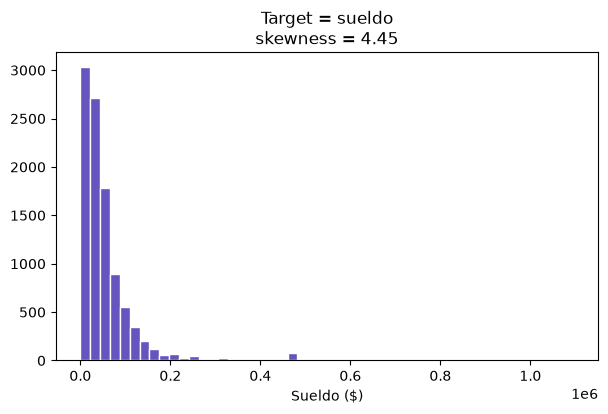

In [65]:
fig, ax = plt.subplots(figsize=(7, 4))
histograma(ax, df["income"], "Target = sueldo")
ax.set_xlabel("Sueldo ($)")
plt.show()

In [66]:
df["income"].describe()

count     10000.00
mean      54406.83
std       68071.30
min         110.00
25%       19000.00
50%       36400.00
75%       65000.00
max     1096000.00
Name: income, dtype: float64

Como se puede observar la target tiene asimetría positiva. Por esta razón, a continuación realizamos la transformación logarítmica ya que tiene valores > 0.

In [67]:
income_log = np.log(df["income"])
income = df["income"].to_numpy()
print(f"Skewness de la target original: {fmt(skew(income))}")
print(f"Skewness de la target transformada con log: {fmt(skew(income_log))}")

Skewness de la target original: 4.45
Skewness de la target transformada con log: -1.01


Como dio un valor negativo probamos con transformación Box-Cox

In [68]:
bc = PowerTransformer(method="box-cox", standardize=False) # standardize = false porque no es necesario para la target. Sí lo sería para features.

income_bc = bc.fit_transform(income.reshape(-1, 1)).ravel()

print(f"λ elegido: {fmt(bc.lambdas_[0])}") #lambdas_ es un array que devuelve el mejor lambda
print(f"Skewness de la target original: {fmt(skew(income))}")
print(f"Skewness de la target transformada con Box-Cox: {fmt(skew(income_bc))}")

λ elegido: 0.21
Skewness de la target original: 4.45
Skewness de la target transformada con Box-Cox: 0.06


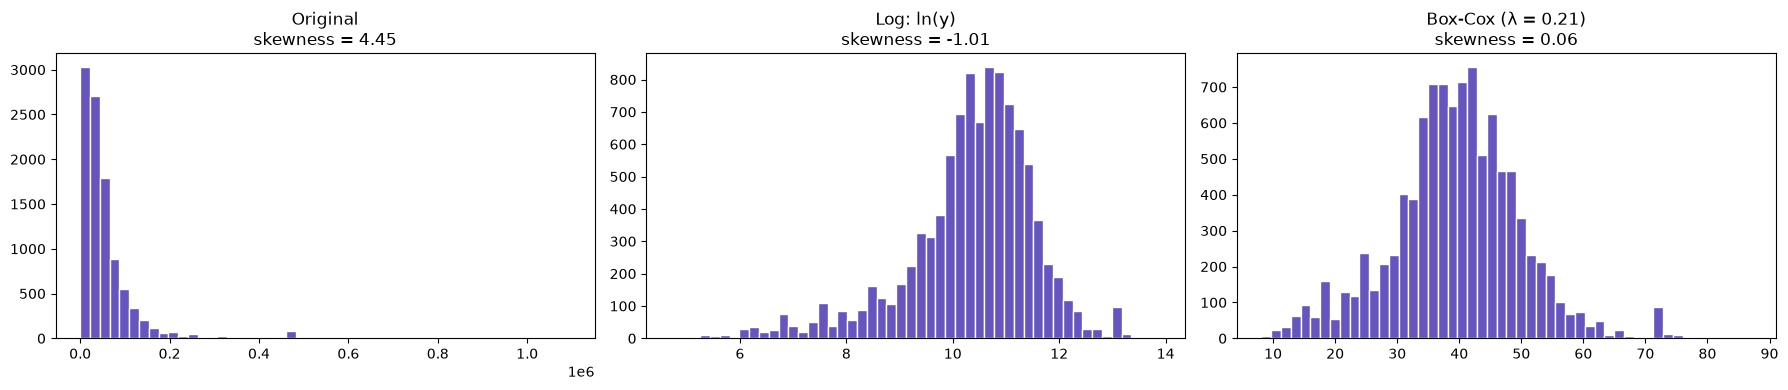

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
histograma(axes[0], income, "Original")
histograma(axes[1], income_log, "Log: ln(y)")
histograma(axes[2], income_bc, f"Box-Cox (λ = {fmt(bc.lambdas_[0])})")
plt.tight_layout()
plt.show()

### Modelo de regresión lineal

In [70]:
# 1. Separar features y target, y apartar el test final
X = df.drop(columns="income")
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Definición del preprocesamiento 
num_cols = ["age", "hours_per_week"]
cat_cols = ["education", "employer_type", "marital_status", "sex", "race", "born_in_us"]

preprocesamiento = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]), cat_cols),
])

# 3. Modelo: preprocesamiento + regresión, con Box-Cox sobre la target
modelo = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", preprocesamiento),
        ("reg", LinearRegression()),
    ]),
    transformer=PowerTransformer(method="box-cox"),
)

# 4. K-fold cross validation sobre el train
kf = KFold(n_splits=5, shuffle=True, random_state=42)

resultados = cross_validate(
    modelo, X_train, y_train, cv=kf,
    scoring=["r2", "neg_root_mean_squared_error"],
    return_train_score=True,
)

print("R² por fold:", resultados["test_r2"].round(3))
print(f"R² medio CV: {resultados['test_r2'].mean():.3f} ± {resultados['test_r2'].std():.3f}")
print(f"RMSE medio CV: {-resultados['test_neg_root_mean_squared_error'].mean():,.0f}")
print(f"R² medio train: {resultados['train_r2'].mean():.3f}")

# 5. Entrenamiento final y evaluación única en test
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print(f"R² test: {r2_score(y_test, y_pred):.3f}")
print(f"RMSE test: {root_mean_squared_error(y_test, y_pred):,.0f}")


R² por fold: [0.312 0.211 0.235 0.268 0.235]
R² medio CV: 0.252 ± 0.035
RMSE medio CV: 59,316
R² medio train: 0.251
R² test: 0.228
RMSE test: 57,463


R² en train ≈ R² en validación (los dos dan ≈ 0.25): no hay sobreajuste.

El R² de test se parece al de CV: la estimación de k-fold era confiable, que es justamente lo que te garantiza no tener leakage.

R² bajo (≈ 0.25): con estas pocas variables y un modelo lineal, el sueldo se explica solo en parte. No es un problema del método.

Conclusión: todas las transformaciones (imputación, escalado, codificación y Box-Cox de la target) están dentro de un Pipeline. Así, en cada fold se ajustan solo con los datos de entrenamiento de ese fold y se aplican al fold de validación sin haberlo visto. El conjunto de test se separa antes de todo y se usa una sola vez al final

### MAE

In [71]:
pipe = Pipeline([
    ("prep", preprocesamiento),
    ("reg", LinearRegression()),
])

modelos = {
    "Target original": clone(pipe),
    "Target log": TransformedTargetRegressor(
        regressor=clone(pipe), func=np.log, inverse_func=np.exp
    ),
    "Target Box-Cox": TransformedTargetRegressor(
        regressor=clone(pipe), transformer=PowerTransformer(method="box-cox")
    ),
}

filas = []
for nombre, modelo_mae in modelos.items():
    cv = cross_validate(modelo_mae, X_train, y_train, cv=kf,
                        scoring=["neg_mean_absolute_error", "r2"])
    modelo_mae.fit(X_train, y_train)
    y_pred = modelo_mae.predict(X_test)

    filas.append({
        "Modelo": nombre,
        "MAE CV (media)": -cv["test_neg_mean_absolute_error"].mean(),
        "MAE CV (std)": cv["test_neg_mean_absolute_error"].std(),
        "R² CV": cv["test_r2"].mean(),
        "MAE test": mean_absolute_error(y_test, y_pred),
        "Predicciones < 0": (y_pred < 0).sum(),
    })

pd.DataFrame(filas).set_index("Modelo")


,MAE CV (media),MAE CV (std),R² CV,MAE test,Predicciones < 0
Modelo,,,,,
Target original,31452.65,1079.93,0.27,30185.66,135
Target log,29494.69,1731.31,0.19,28928.32,0
Target Box-Cox,28116.01,1514.80,0.25,27466.87,0


Box-Cox tiene el menor MAE. Reduce el error absoluto medio en unos $3.300 frente a la target original (≈ 11 % menos). La mejora se repite en CV y en test, así que no depende de una partición puntual.

La target original genera predicciones imposibles. El modelo lineal sobre la target sin transformar predice sueldos negativos en 135 casos del test (el mínimo es −$53.000). Al transformar, la inversa siempre devuelve valores positivos.

El log mejora respecto de la original, pero menos que Box-Cox. Esto confirma lo que viste con la skewness: el log corrige de más (skew −1.01). Box-Cox, con λ = 0.21, ajusta mejor y por eso también predice mejor.

¿Por qué el R² de la original es un poco más alto? El R² se basa en errores al cuadrado, así que pesa mucho los sueldos extremos (hay valores de hasta $1.096.000). El modelo sin transformar intenta acercarse a esos extremos, lo que favorece el R² pero empeora la mayoría de las predicciones. Las transformaciones comprimen la cola derecha y priorizan el error en los sueldos típicos, que es lo que mide el MAE. Es un buen punto para mencionar: la mejor métrica depende de qué errores te importan más.

Limitación. Al volver a pesos con la inversa, el modelo transformado predice algo más parecido a la mediana del sueldo que a la media condicional. Por eso tiende a subestimar los sueldos muy altos. Para el MAE eso es una ventaja: la mediana es justamente lo que minimiza el error absoluto.

Conclusión: transformar la target con Box-Cox mejora el MAE (≈ $28.100 contra ≈ $31.500 con la original) y evita predicciones negativas, a costa de un R² apenas menor, sensible a los sueldos extremos. Por eso elegimos el modelo con target Box-Cox

## Parte 2

### Auditoría de sesgos

In [72]:
pipe_entrenado = modelo.regressor_                # Pipeline ajustado (el que está adentro del TTR)
prep = pipe_entrenado.named_steps["prep"]         # ColumnTransformer ajustado
reg = pipe_entrenado.named_steps["reg"]           # LinearRegression ajustado

nombres = prep.get_feature_names_out()

def preprocesar(X):
    Xt = prep.transform(X)
    if hasattr(Xt, "toarray"):
        Xt = Xt.toarray()
    return pd.DataFrame(Xt, columns=nombres, index=X.index)

X_train_prep = preprocesar(X_train)
X_test_prep = preprocesar(X_test)

explainer = shap.LinearExplainer(reg, X_train_prep)
explanation = explainer(X_test_prep)


Como las variables categóricas se codificaron con one-hot, SHAP asigna un valor a cada categoría por separado, interpretado respecto de la categoría de referencia. Para medir la importancia total de cada variable original, sumamos los valores SHAP de sus dummies, aprovechando que SHAP es aditivo

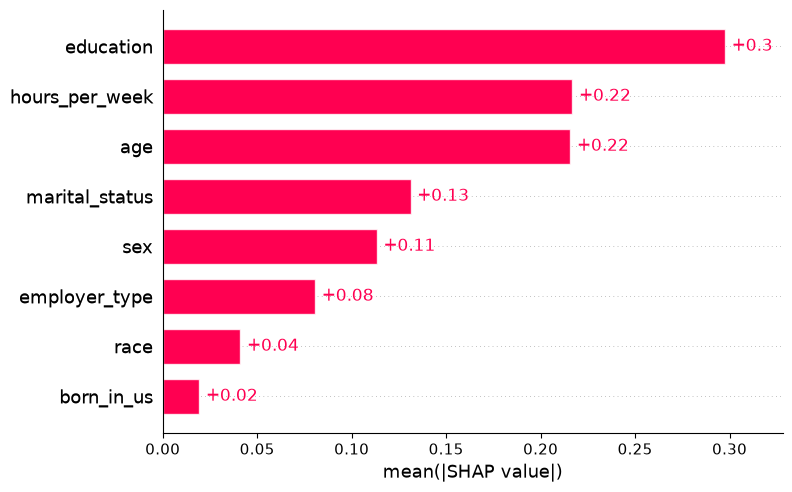

In [73]:
originales = num_cols + cat_cols

def variable_original(nombre):
    nombre = nombre.split("__", 1)[1]             # saca el prefijo "num__" / "cat__"
    return next(c for c in originales if nombre == c or nombre.startswith(c + "_"))

grupos = [variable_original(n) for n in explanation.feature_names]

# Sumar los SHAP de las dummies que vienen de la misma variable original
valores_agrupados = (
    pd.DataFrame(explanation.values, columns=grupos)
    .T.groupby(level=0).sum().T
)

# Valores para colorear el beeswarm: numéricas con su valor real,
# categóricas en NaN (se dibujan en gris porque no tienen un orden "alto/bajo")
datos = X_test[valores_agrupados.columns].copy()
datos[cat_cols] = np.nan

expl_agrupada = shap.Explanation(
    values=valores_agrupados.to_numpy(),
    base_values=explanation.base_values,
    data=datos.to_numpy(dtype=float),
    feature_names=list(valores_agrupados.columns),
)

shap.plots.bar(expl_agrupada)



c:\Users\tatia\.conda\envs\add2-env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


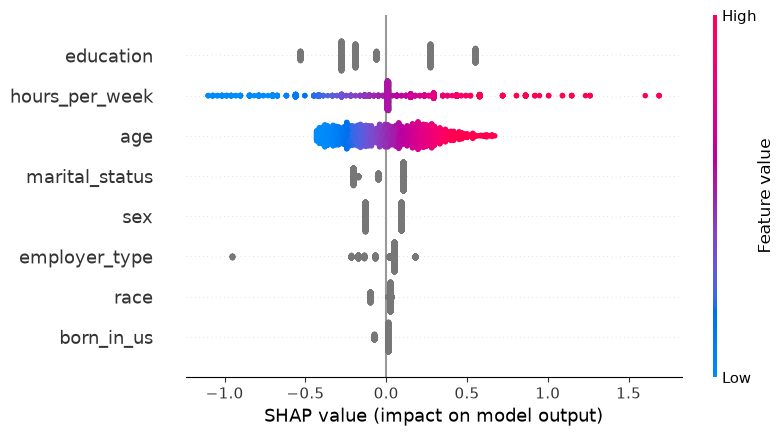

In [74]:
shap.plots.beeswarm(expl_agrupada)

In [75]:
A_train = X_train["sex"]
A_test = X_test["sex"]

# Explicación sin la columna "sex" (para ver cómo usa el modelo el resto de las variables en cada grupo)
features_sin_sex = [i for i, n in enumerate(expl_agrupada.feature_names) if n != "sex"]
expl_sin_sex = expl_agrupada[:, features_sin_sex]

mask_mujeres = (A_test == "Female").to_numpy()
mask_hombres = (A_test == "Male").to_numpy()


c:\Users\tatia\.conda\envs\add2-env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


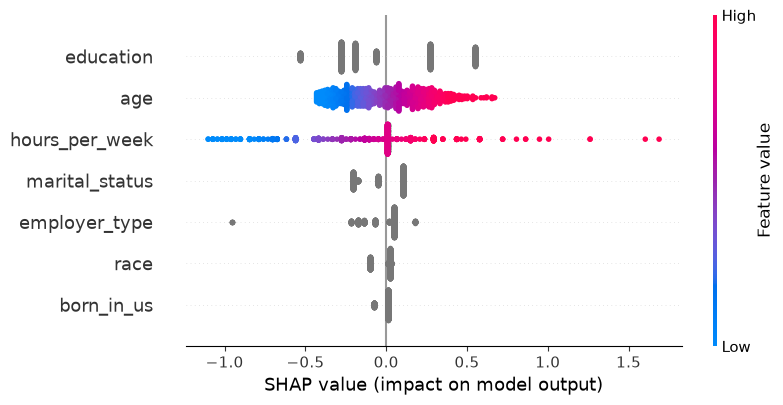

In [76]:
shap.plots.beeswarm(expl_sin_sex[mask_mujeres])

c:\Users\tatia\.conda\envs\add2-env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


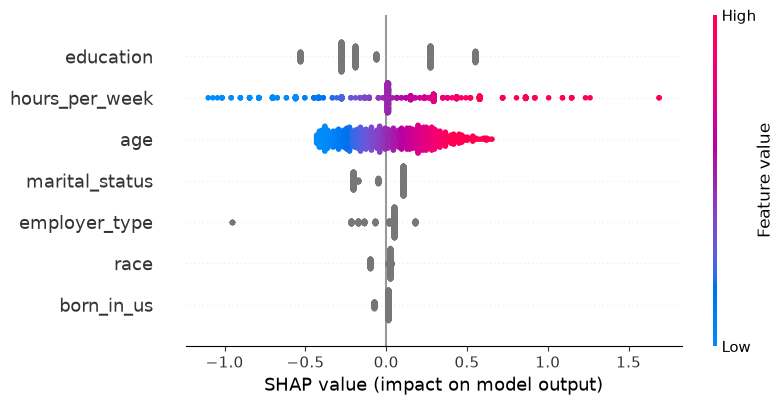

In [77]:
shap.plots.beeswarm(expl_sin_sex[mask_hombres])

race = Black  (n = 476)


c:\Users\tatia\.conda\envs\add2-env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


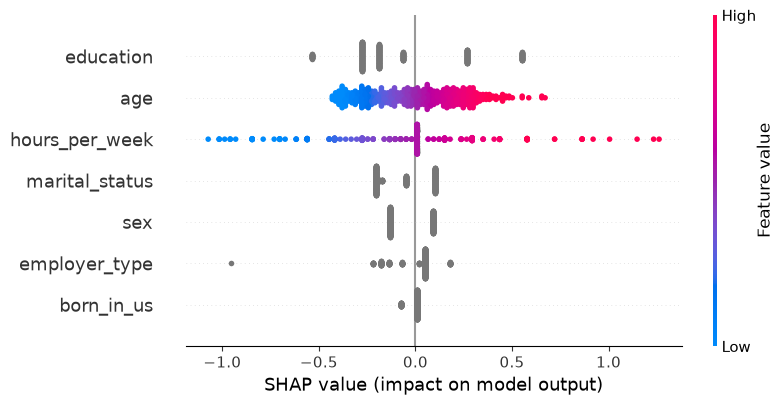

race = White  (n = 1357)


c:\Users\tatia\.conda\envs\add2-env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


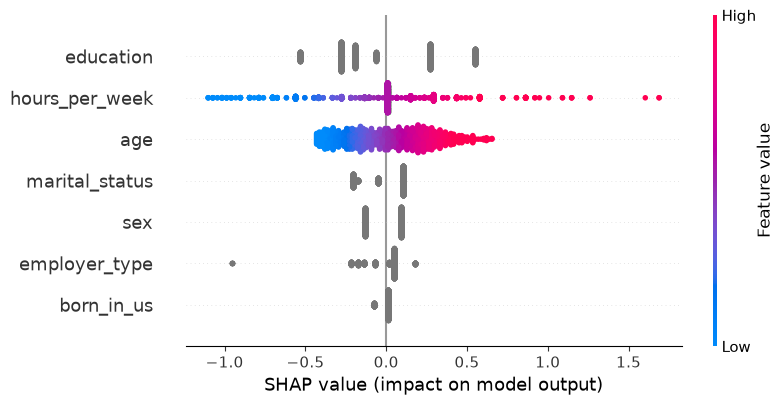

race = Asian  (n = 90)


c:\Users\tatia\.conda\envs\add2-env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


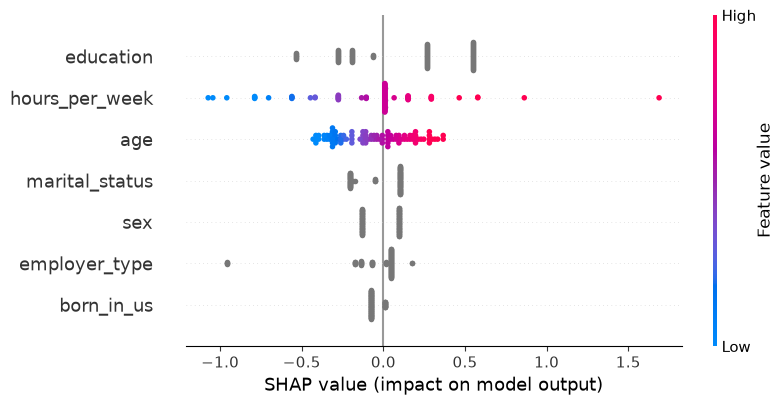

race = Other or multiple  (n = 77)


c:\Users\tatia\.conda\envs\add2-env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


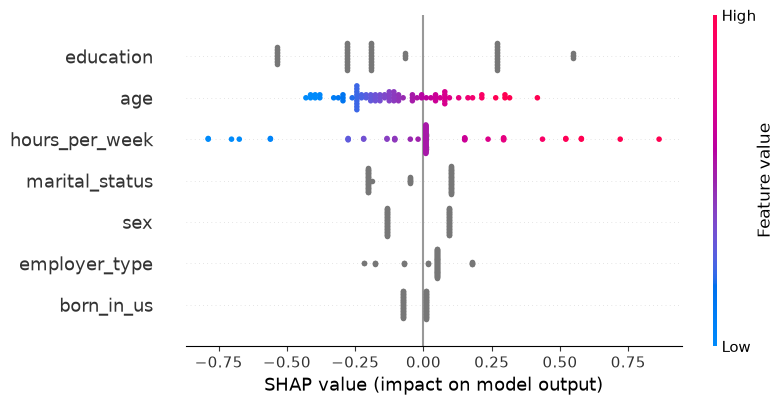

In [78]:
features_sin_race = [i for i, n in enumerate(expl_agrupada.feature_names) if n != "race"]
expl_sin_race = expl_agrupada[:, features_sin_race]

for grupo in X_test["race"].unique():
    mask = (X_test["race"] == grupo).to_numpy()
    print(f"race = {grupo}  (n = {mask.sum()})")
    shap.plots.beeswarm(expl_sin_race[mask])


In [79]:
y_pred = pd.Series(modelo.predict(X_test), index=X_test.index)
mae_global = mean_absolute_error(y_test, y_pred)

def metricas_por_grupo(col):
    filas = []
    for grupo, idx in X_test.groupby(col).groups.items():
        yt, yp = y_test.loc[idx], y_pred.loc[idx]
        mae = mean_absolute_error(yt, yp)
        filas.append({
            col: grupo,
            "n": len(idx),
            "Sueldo real medio": yt.mean(),
            "Predicción media": yp.mean(),
            "MAE": mae,
            "MAE relativo": mae / yt.mean(),
            "Error medio (pred - real)": (yp - yt).mean(),
            "MAE / MAE global": mae / mae_global,
        })
    return pd.DataFrame(filas).set_index(col)

metricas_por_grupo("sex")


,n,Sueldo real medio,Predicción media,MAE,MAE relativo,Error medio (pred - real),MAE / MAE global
sex,,,,,,,
Female,1008,44414.10,35123.37,22127.33,0.50,-9290.73,0.81
Male,992,64170.62,51554.75,32892.54,0.51,-12615.87,1.20


In [80]:
metricas_por_grupo("race")

,n,Sueldo real medio,Predicción media,MAE,MAE relativo,Error medio (pred - real),MAE / MAE global
race,,,,,,,
Asian,90,55437.00,45575.21,26837.96,0.48,-9861.79,0.98
Black,476,39917.63,33398.07,19262.47,0.48,-6519.55,0.70
Other or multiple,77,41184.42,34312.78,19031.70,0.46,-6871.63,0.69
White,1357,59886.03,47093.09,30865.11,0.52,-12792.94,1.12


In [81]:
for col in ["sex", "race"]:
    idx = expl_agrupada.feature_names.index(col)
    shap_medio = pd.Series(expl_agrupada.values[:, idx], index=X_test.index).groupby(X_test[col]).mean()
    print(f"SHAP medio de '{col}' por grupo:\n{shap_medio.round(3)}\n")


SHAP medio de 'sex' por grupo:
sex
Female   -0.13
Male      0.09
dtype: float64

SHAP medio de 'race' por grupo:
race
Asian                0.03
Black               -0.10
Other or multiple    0.01
White                0.02
dtype: float64



### Model Card

In [82]:
carpeta_card = Path("model_card")
carpeta_card.mkdir(exist_ok=True)

mc = card.Card(modelo, template=None, model_diagram=False)

In [83]:
lambda_bc = modelo.transformer_.lambdas_[0]

mc.add(**{
    "Detalles del modelo": (
        f"- **Nombre:** Predicción de sueldo anual (Census income)\n"
        f"- **Versión:** 1.0\n"
        f"- **Fecha:** {pd.Timestamp.today():%d/%m/%Y}\n"
        f"- **Responsable:** Tatiana Duran (a2521)\n"
        f"- **Tipo de modelo:** regresión lineal (`LinearRegression`) dentro de un `Pipeline`, "
        f"con la target transformada con Box-Cox (λ = {lambda_bc:.2f}) mediante `TransformedTargetRegressor`\n"
        f"- **Preprocesamiento:** imputación (mediana en numéricas, moda en categóricas), "
        f"estandarización de numéricas y one-hot de categóricas, todo ajustado solo con datos de entrenamiento"
    ),
    "Propósito": (
        "Estimar el sueldo anual de una persona a partir de variables demográficas y laborales. "
        "Es un modelo con fines académicos (Actividad 4, Análisis de Datos II), pensado para practicar "
        "feature engineering, prevención de data leakage y auditoría de sesgos."
    ),
    "Entradas y salidas": (
        f"- **Entradas ({X.shape[1]} variables):**\n"
        f"  - Numéricas: {', '.join(f'`{c}`' for c in num_cols)}\n"
        f"  - Categóricas: {', '.join(f'`{c}`' for c in cat_cols)}\n"
        f"  - Admite valores faltantes en las entradas (se imputan dentro del pipeline).\n"
        f"- **Salida:** sueldo anual estimado en pesos (`income`), siempre positivo. "
        f"El modelo predice en escala Box-Cox y devuelve el valor ya convertido a pesos."
    ),
    "Datos": (
        f"- **Origen:** dataset Census income ({len(df):,} registros).\n"
        f"- **Partición:** {len(X_train):,} para entrenamiento (con k-fold de {kf.get_n_splits()} folds) "
        f"y {len(X_test):,} para test, separados antes de cualquier transformación.\n"
        f"- **Valores faltantes:** "
        + ", ".join(f"`{c}` ({n})" for c, n in df.isna().sum().items() if n > 0) + ".\n"
        f"- **Variables sensibles analizadas:** `sex` y `race`."
    ),
})


Card(
  model=TransformedTargetRegressor(regress...PowerTransformer(method='box-cox')),
  Detalles del modelo=- **Nombre:** Predicción de...o con datos de entrenamiento,
  Propósito=Estimar el sueldo anual de una p...ta leakage y auditoría de sesgos.,
  Entradas y salidas=- **Entradas (8 variables):*...valor ya convertido a pesos.,
  Datos=- **Origen:** dataset Census incom...ibles analizadas:** `sex` y `race`.,
)

In [84]:
y_pred = modelo.predict(X_test)

mc.add_metrics(
    section="Métricas de desempeño",
    description=(
        f"Validación cruzada ({kf.get_n_splits()} folds sobre el train) y evaluación final sobre el conjunto de test. "
        "El MAE y el RMSE están en pesos."
    ),
    **{
        "MAE test": round(mean_absolute_error(y_test, y_pred)),
        "RMSE test": round(root_mean_squared_error(y_test, y_pred)),
        "R² test": round(r2_score(y_test, y_pred), 3),
        "R² CV (media)": round(resultados["test_r2"].mean(), 3),
        "R² CV (desvío)": round(resultados["test_r2"].std(), 3),
    },
)


Card(
  model=TransformedTargetRegressor(regress...PowerTransformer(method='box-cox')),
  Detalles del modelo=- **Nombre:** Predicción de...o con datos de entrenamiento,
  Propósito=Estimar el sueldo anual de una p...ta leakage y auditoría de sesgos.,
  Entradas y salidas=- **Entradas (8 variables):*...valor ya convertido a pesos.,
  Datos=- **Origen:** dataset Census incom...ibles analizadas:** `sex` y `race`.,
  Métricas de desempeño=TableSection(5x2),
)

In [85]:
def mae_relativo(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred) / np.mean(y_true)

def error_medio(y_true, y_pred):
    return np.mean(np.asarray(y_pred) - np.asarray(y_true))

metricas = {
    "n": count,
    "MAE": mean_absolute_error,
    "MAE relativo": mae_relativo,
    "Error medio (pred - real)": error_medio,
}

tablas_grupo = {}
for col in ["sex", "race"]:
    mf_grupo = MetricFrame(metrics=metricas, y_true=y_test, y_pred=y_pred, sensitive_features=X_test[col])
    tablas_grupo[col] = mf_grupo
    tabla = mf_grupo.by_group.reset_index()
    tabla["n"] = tabla["n"].astype(int)
    tabla[["MAE", "Error medio (pred - real)"]] = tabla[["MAE", "Error medio (pred - real)"]].round(0)
    tabla["MAE relativo"] = tabla["MAE relativo"].round(3)
    mc.add(**{f"Métricas por subgrupo/{col}": tabla.to_markdown(index=False)})

# Gráfico: MAE relativo por grupo
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, col in zip(axes, ["sex", "race"]):
    tablas_grupo[col].by_group["MAE relativo"].plot.bar(ax=ax, color="#4E79A7", rot=0, title=f"MAE relativo por {col}")
    ax.axhline(mae_relativo(y_test, y_pred), color="gray", linestyle="--", label="global")
    ax.set_xlabel("")
    ax.legend()
plt.tight_layout()
fig.savefig(carpeta_card / "mae_por_grupo.png", dpi=120)
plt.close(fig)

# Conclusión automática: ¿algún grupo se aleja más de un 20 % del MAE relativo global?
UMBRAL_DISPARIDAD = 0.2
mae_rel_global = mae_relativo(y_test, y_pred)
grupos_alerta = [
    f"{col} = {grupo}"
    for col, mf_grupo in tablas_grupo.items()
    for grupo, valor in mf_grupo.by_group["MAE relativo"].items()
    if abs(valor / mae_rel_global - 1) > UMBRAL_DISPARIDAD
]

if grupos_alerta:
    conclusion = f"**Se detectaron disparidades en el error** en: {', '.join(grupos_alerta)}."
else:
    conclusion = (
        f"El MAE relativo de todos los grupos está dentro de ±{UMBRAL_DISPARIDAD:.0%} del global "
        f"({mae_rel_global:.2f}): el modelo se equivoca en una proporción similar con todos. "
        "El MAE en pesos es mayor en hombres y en personas blancas porque sus sueldos son más altos y dispersos. "
        "Todos los grupos están subestimados (error medio negativo), efecto de la transformación Box-Cox."
    )

mc.add(**{
    "Métricas por subgrupo": (
        "Métricas calculadas con Fairlearn (`MetricFrame`) sobre el conjunto de test. "
        "El **MAE relativo** (MAE / sueldo medio del grupo) permite comparar grupos con niveles de sueldo distintos."
    ),
    "Métricas por subgrupo/Conclusión": conclusion,
})
mc.add_plot(**{"Métricas por subgrupo/Gráfico": "mae_por_grupo.png"})


Card(
  model=TransformedTargetRegressor(regress...PowerTransformer(method='box-cox')),
  Detalles del modelo=- **Nombre:** Predicción de...o con datos de entrenamiento,
  Propósito=Estimar el sueldo anual de una p...ta leakage y auditoría de sesgos.,
  Entradas y salidas=- **Entradas (8 variables):*...valor ya convertido a pesos.,
  Datos=- **Origen:** dataset Census incom...ibles analizadas:** `sex` y `race`.,
  Métricas de desempeño=TableSection(5x2),
  Métricas por subgrupo=Métricas calculadas con Fa...iveles de sueldo distintos.,
  Métricas por subgrupo/sex=| sex | n | MAE | MAE re... 32893 | 0.513 | -12616 |,
  Métricas por subgrupo/race=| race | n | MAE | MAE r...30865 | 0.515 | -12793 |,
  Métricas por subgrupo/Conclusión=El MAE relativo de to...ansformación Box-Cox.,
  Métricas por subgrupo/Gráfico=PlotSection(mae_por_grupo.png),
)

In [86]:
importancia = pd.Series(np.abs(expl_agrupada.values).mean(axis=0), index=expl_agrupada.feature_names).sort_values()

fig, ax = plt.subplots(figsize=(6, 3))
importancia.plot.barh(ax=ax, color="#4E79A7")
ax.set_title("Importancia SHAP (media de |SHAP|, test)")
ax.set_xlabel("Escala Box-Cox estandarizada")
plt.tight_layout()
fig.savefig(carpeta_card / "importancia_shap.png", dpi=120)
plt.close(fig)

ranking = list(importancia.sort_values(ascending=False).index)
idx_sex = expl_agrupada.feature_names.index("sex")
shap_sex = pd.Series(expl_agrupada.values[:, idx_sex], index=X_test.index).groupby(X_test["sex"]).mean()

mc.add(**{
    "Explicabilidad": (
        f"Valores SHAP (`LinearExplainer`) agrupando las dummies de cada variable original. "
        f"`sex` ocupa el puesto {ranking.index('sex') + 1} y `race` el puesto {ranking.index('race') + 1} "
        f"de {len(ranking)} en importancia. En promedio, `sex` baja la predicción de las mujeres "
        f"({shap_sex['Female']:+.2f}) y sube la de los hombres ({shap_sex['Male']:+.2f}): "
        "el modelo usa la variable sensible directamente."
    )
})
mc.add_plot(**{"Explicabilidad/Importancia SHAP": "importancia_shap.png"})


Card(
  model=TransformedTargetRegressor(regress...PowerTransformer(method='box-cox')),
  Detalles del modelo=- **Nombre:** Predicción de...o con datos de entrenamiento,
  Propósito=Estimar el sueldo anual de una p...ta leakage y auditoría de sesgos.,
  Entradas y salidas=- **Entradas (8 variables):*...valor ya convertido a pesos.,
  Datos=- **Origen:** dataset Census incom...ibles analizadas:** `sex` y `race`.,
  Métricas de desempeño=TableSection(5x2),
  Métricas por subgrupo=Métricas calculadas con Fa...iveles de sueldo distintos.,
  Métricas por subgrupo/sex=| sex | n | MAE | MAE re... 32893 | 0.513 | -12616 |,
  Métricas por subgrupo/race=| race | n | MAE | MAE r...30865 | 0.515 | -12793 |,
  Métricas por subgrupo/Conclusión=El MAE relativo de to...ansformación Box-Cox.,
  Métricas por subgrupo/Gráfico=PlotSection(mae_por_grupo.png),
  Explicabilidad=Valores SHAP (`LinearExplainer...ariable sensible directamente.,
  Explicabilidad/Importancia SHAP=PlotSection(importancia_shap.png)

In [87]:
pred_media = pd.Series(y_pred, index=X_test.index).groupby(X_test["sex"]).mean()

mc.add(**{
    "Limitaciones de uso": (
        f"- **Reproduce la brecha salarial histórica:** predice en promedio ${pred_media['Female']:,.0f} para mujeres "
        f"y ${pred_media['Male']:,.0f} para hombres, en parte por usar `sex` y `race` como predictores directos.\n"
        "- **No usar para decisiones sobre personas** (fijar salarios, aprobar créditos, selección de personal): "
        "perpetuaría las desigualdades presentes en los datos.\n"
        f"- **Capacidad predictiva limitada:** R² ≈ {r2_score(y_test, y_pred):.2f}; "
        f"el error absoluto medio es de ${mean_absolute_error(y_test, y_pred):,.0f}.\n"
        "- **Subestima los sueldos altos:** por la transformación Box-Cox, la predicción se acerca a la mediana y no a la media.\n"
        "- **Grupos chicos:** las métricas de `race` = Asian y Other or multiple se basan en menos de 100 casos del test.\n"
        "- **Proxies:** quitar `sex` y `race` no garantiza eliminar el sesgo, porque variables como `marital_status` "
        "pueden estar correlacionadas con ellas.\n"
        f"- **Rango de validez:** edades entre {df['age'].min()} y {df['age'].max()} años; "
        "no se garantiza el desempeño en poblaciones distintas a la de entrenamiento."
    ),
})


Card(
  model=TransformedTargetRegressor(regress...PowerTransformer(method='box-cox')),
  Detalles del modelo=- **Nombre:** Predicción de...o con datos de entrenamiento,
  Propósito=Estimar el sueldo anual de una p...ta leakage y auditoría de sesgos.,
  Entradas y salidas=- **Entradas (8 variables):*...valor ya convertido a pesos.,
  Datos=- **Origen:** dataset Census incom...ibles analizadas:** `sex` y `race`.,
  Métricas de desempeño=TableSection(5x2),
  Métricas por subgrupo=Métricas calculadas con Fa...iveles de sueldo distintos.,
  Métricas por subgrupo/sex=| sex | n | MAE | MAE re... 32893 | 0.513 | -12616 |,
  Métricas por subgrupo/race=| race | n | MAE | MAE r...30865 | 0.515 | -12793 |,
  Métricas por subgrupo/Conclusión=El MAE relativo de to...ansformación Box-Cox.,
  Métricas por subgrupo/Gráfico=PlotSection(mae_por_grupo.png),
  Explicabilidad=Valores SHAP (`LinearExplainer...ariable sensible directamente.,
  Explicabilidad/Importancia SHAP=PlotSection(importancia_shap.png)

In [88]:
print(mc.get_toc())
mc.save(carpeta_card / "README.md")
print("Model Card guardada en:", carpeta_card / "README.md")

- Detalles del modelo
- Propósito
- Entradas y salidas
- Datos
- Métricas de desempeño
- Métricas por subgrupo
  - sex
  - race
  - Conclusión
  - Gráfico
- Explicabilidad
  - Importancia SHAP
- Limitaciones de uso
Model Card guardada en: model_card\README.md
